In [0]:
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

CATALOG = "imaginex"
SCHEMA  = "nba"

current = spark.table(f"{CATALOG}.{SCHEMA}.gold_v_player_current")
fact    = spark.table(f"{CATALOG}.{SCHEMA}.gold_fact_player_snapshot")

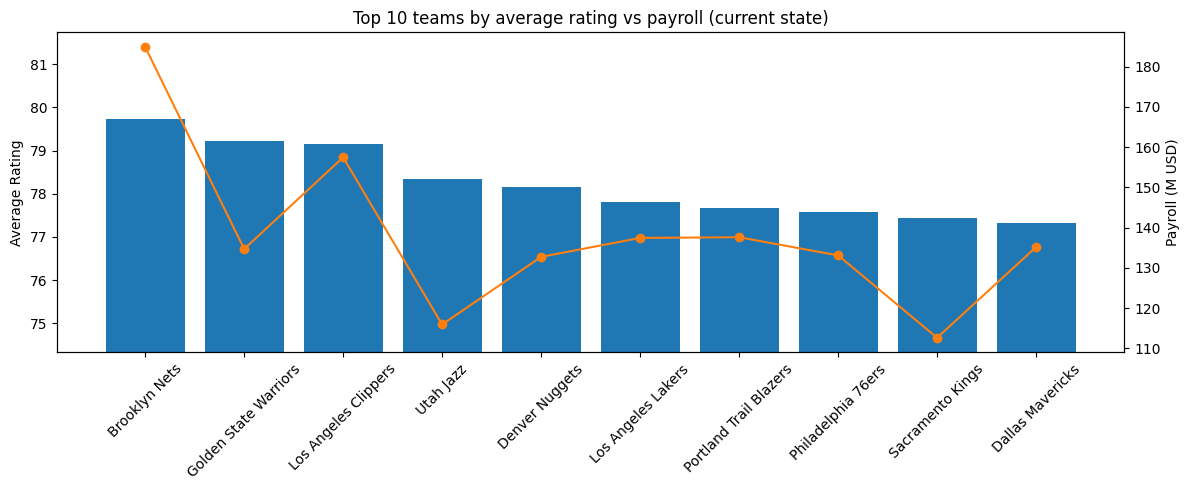

In [0]:
team_pdf = (
    current.filter(F.col("team_name").isNotNull())
           .groupBy("team_name")
           .agg(F.avg("rating").alias("avg_rating"),
                (F.sum("salary_usd") / 1e6).alias("payroll_musd"))
           .orderBy(F.desc("avg_rating"))
           .limit(10)
           .toPandas()
)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(team_pdf["team_name"], team_pdf["avg_rating"], color="#1f77b4")
ax1.set_ylabel("Average Rating")
ax1.set_ylim(team_pdf["avg_rating"].min() - 3, team_pdf["avg_rating"].max() + 2)
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(team_pdf["team_name"], team_pdf["payroll_musd"], color="#ff7f0e", marker="o")
ax2.set_ylabel("Payroll (M USD)")

plt.title("Top 10 teams by average rating vs payroll (current state)")
plt.tight_layout()
plt.show()

Correlation rating vs salary: 0.79


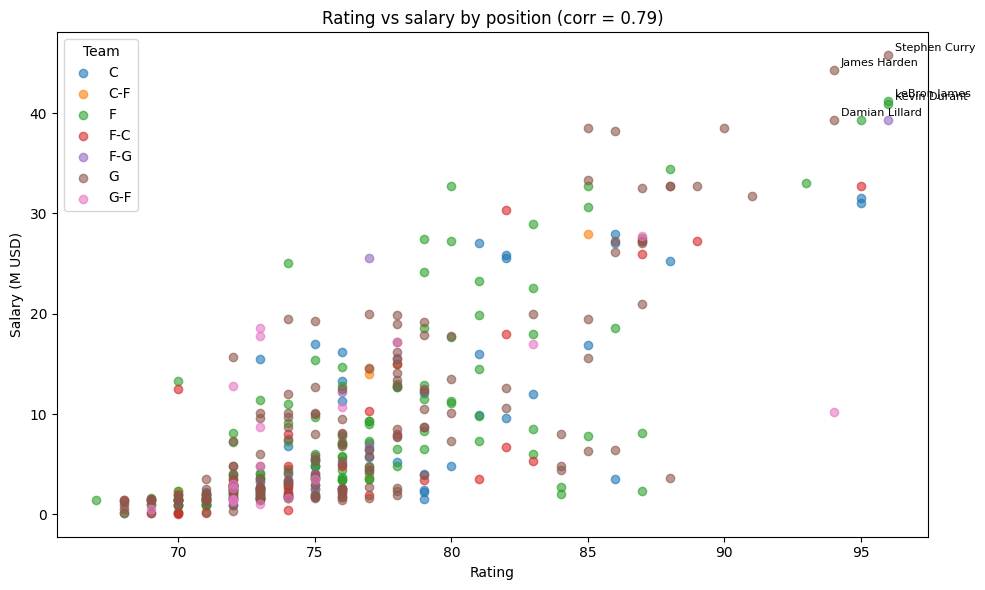

In [0]:
pdf = (
    current.filter("salary_usd IS NOT NULL AND rating IS NOT NULL")
           .select("full_name", "position", "rating",
                   (F.col("salary_usd") / 1e6).alias("salary_musd"))
           .toPandas()
)

corr = pdf["rating"].corr(pdf["salary_musd"])
print(f"Correlation rating vs salary: {corr:.2f}")

fig, ax = plt.subplots(figsize=(10, 6))
for pos, grp in pdf.groupby("position"):
    ax.scatter(grp["rating"], grp["salary_musd"], label=pos, alpha=0.6)

# Top 5 mejor pagados, etiquetados
for _, r in pdf.nlargest(5, "salary_musd").iterrows():
    ax.annotate(r["full_name"], (r["rating"], r["salary_musd"]), fontsize=8,
                xytext=(5, 3), textcoords="offset points")

ax.set_xlabel("Rating")
ax.set_ylabel("Salary (M USD)")
ax.set_title(f"Rating vs salary by position (corr = {corr:.2f})")
ax.legend(title="Team")
plt.tight_layout()
plt.show()